In [2]:
# ============================================================
# DIAMOND PRICE PREDICTION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Models
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# ============================================================
# CELL 2 — LOAD DATASET
# ============================================================

# Load the cleaned standard diamond dataset
file_path = "../data/diamonds (1).csv"

df = pd.read_csv(file_path)

print("=" * 60)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

DATASET LOADED SUCCESSFULLY
Rows    : 53940
Columns : 11

Column Names:
['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

First 5 Rows:


,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [4]:
# ============================================================
# CELL 3 — DATA CLEANING & QUALITY CHECK
# ============================================================

# Remove unnecessary index column
df = df.drop(columns=["Unnamed: 0"])

# Check duplicate rows
duplicate_count = df.duplicated().sum()

# Check missing values
missing_values = df.isnull().sum()

print("=" * 60)
print("DATA CLEANING")
print("=" * 60)

print(f"Duplicate rows found : {duplicate_count}")

print("\nMissing values:")
print(missing_values)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("\n" + "=" * 60)
print("CLEAN DATASET")
print("=" * 60)

print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

print("\nRemaining duplicate rows:", df.duplicated().sum())
print("Total missing values   :", df.isnull().sum().sum())

DATA CLEANING
Duplicate rows found : 146

Missing values:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

CLEAN DATASET
Rows    : 53794
Columns : 10

Remaining duplicate rows: 0
Total missing values   : 0


In [5]:
# ============================================================
# CELL 4 — DATASET OVERVIEW
# ============================================================

print("=" * 60)
print("DATA TYPES")
print("=" * 60)

print(df.dtypes)

print("\n" + "=" * 60)
print("STATISTICAL SUMMARY")
print("=" * 60)

display(df.describe())

print("\n" + "=" * 60)
print("CATEGORICAL FEATURES")
print("=" * 60)

for col in ["cut", "color", "clarity"]:
    print(f"\n{col.upper()}:")
    print(df[col].value_counts())

DATA TYPES
carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
price        int64
x          float64
y          float64
z          float64
dtype: object

STATISTICAL SUMMARY


,carat,depth,table,price,x,y,z
count,53794.00000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000,53794.000000
mean,0.79778,61.748080,57.458109,3933.065082,5.731214,5.734653,3.538714
std,0.47339,1.429909,2.233679,3988.114460,1.120695,1.141209,0.705037
min,0.20000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.40000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.70000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.04000,62.500000,59.000000,5326.750000,6.540000,6.540000,4.030000
max,5.01000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000



CATEGORICAL FEATURES

CUT:
cut
Ideal        21488
Premium      13748
Very Good    12069
Good          4891
Fair          1598
Name: count, dtype: int64

COLOR:
color
G    11262
E     9776
F     9520
H     8272
D     6755
I     5407
J     2802
Name: count, dtype: int64

CLARITY:
clarity
SI1     13032
VS2     12229
SI2      9150
VS1      8156
VVS2     5056
VVS1     3647
IF       1784
I1        740
Name: count, dtype: int64


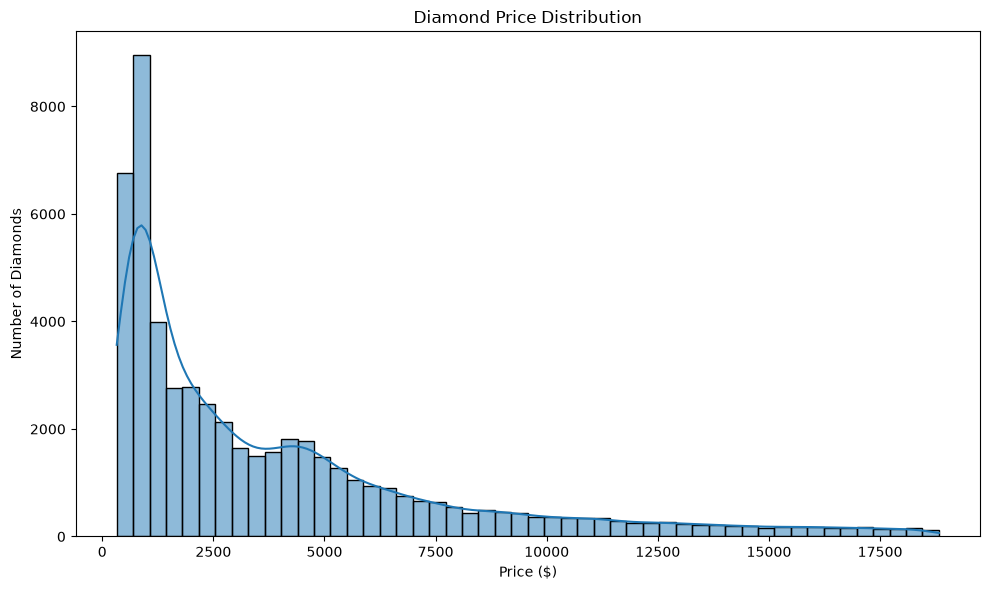

In [6]:
# ============================================================
# CELL 5 — PRICE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    df["price"],
    bins=50,
    kde=True
)

plt.title("Diamond Price Distribution")
plt.xlabel("Price ($)")
plt.ylabel("Number of Diamonds")
plt.tight_layout()
plt.show()


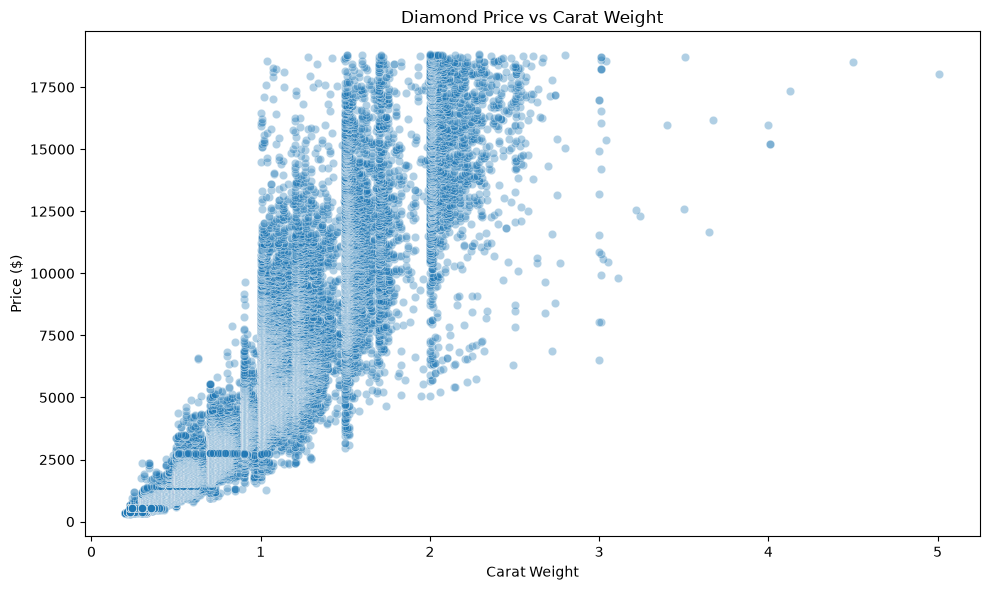

In [7]:
# ============================================================
# CELL 6 — CARAT VS PRICE
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="carat",
    y="price",
    alpha=0.35
)

plt.title("Diamond Price vs Carat Weight")
plt.xlabel("Carat Weight")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

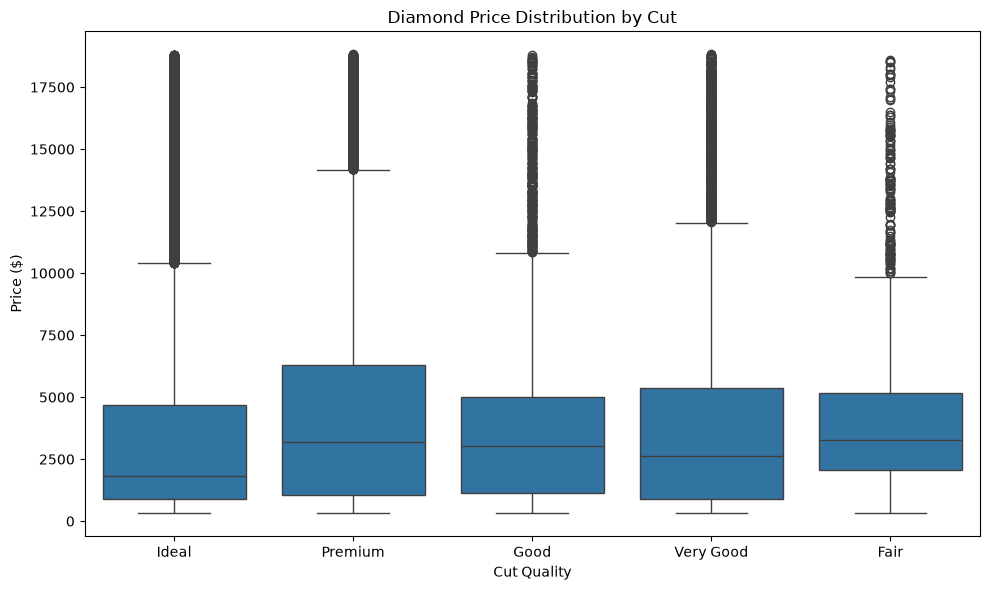

In [8]:
# ============================================================
# CELL 7 — PRICE BY CUT
# ============================================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="cut",
    y="price"
)

plt.title("Diamond Price Distribution by Cut")
plt.xlabel("Cut Quality")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

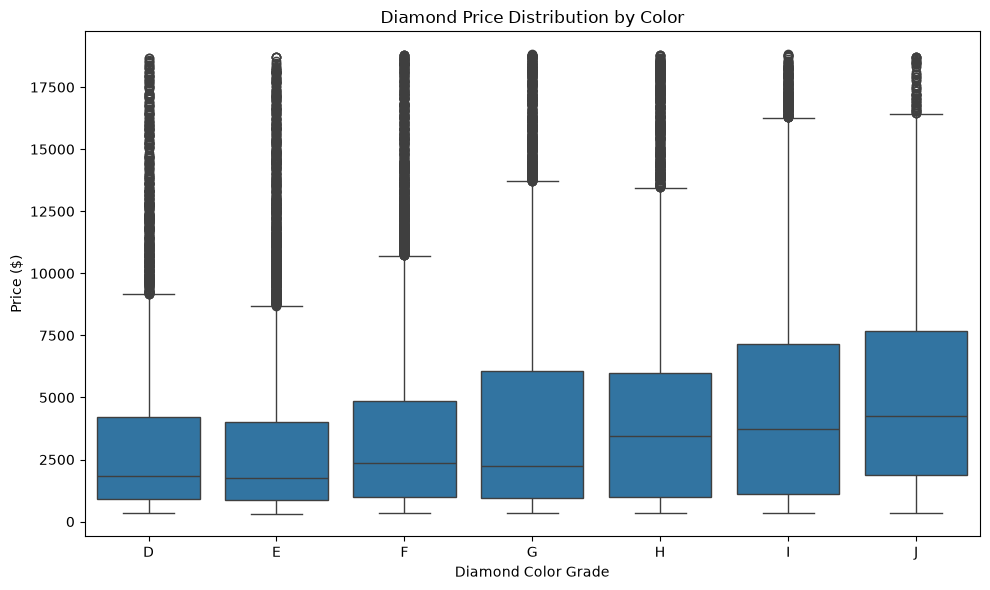

In [9]:
# ============================================================
# CELL 8 — PRICE BY COLOR
# ============================================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="color",
    y="price",
    order=["D", "E", "F", "G", "H", "I", "J"]
)

plt.title("Diamond Price Distribution by Color")
plt.xlabel("Diamond Color Grade")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

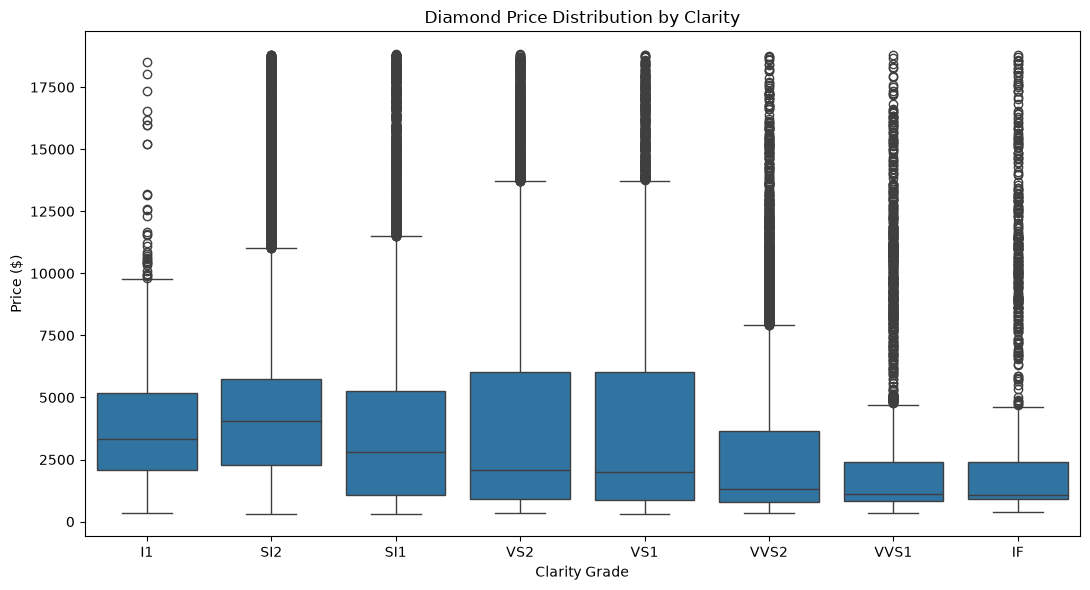

In [10]:
# ============================================================
# CELL 9 — PRICE BY CLARITY
# ============================================================

clarity_order = [
    "I1",
    "SI2",
    "SI1",
    "VS2",
    "VS1",
    "VVS2",
    "VVS1",
    "IF"
]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="clarity",
    y="price",
    order=clarity_order
)

plt.title("Diamond Price Distribution by Clarity")
plt.xlabel("Clarity Grade")
plt.ylabel("Price ($)")
plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# CELL 10 — FEATURES AND TARGET
# ============================================================

# Target variable
target = "price"

# Separate features and target
X = df.drop(columns=[target])
y = df[target]

print("=" * 60)
print("FEATURES AND TARGET")
print("=" * 60)

print(f"Features shape : {X.shape}")
print(f"Target shape   : {y.shape}")

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(target)

print("\nTarget statistics:")
print(y.describe())

FEATURES AND TARGET
Features shape : (53794, 9)
Target shape   : (53794,)

Features:
['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z']

Target:
price

Target statistics:
count    53794.000000
mean      3933.065082
std       3988.114460
min        326.000000
25%        951.000000
50%       2401.000000
75%       5326.750000
max      18823.000000
Name: price, dtype: float64


In [12]:
# ============================================================
# CELL 11 — TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

print(f"Total samples : {len(X)}")
print(f"Training data : {len(X_train)}")
print(f"Testing data  : {len(X_test)}")

print(f"\nTraining percentage : {len(X_train) / len(X) * 100:.1f}%")
print(f"Testing percentage  : {len(X_test) / len(X) * 100:.1f}%")

TRAIN / TEST SPLIT
Total samples : 53794
Training data : 43035
Testing data  : 10759

Training percentage : 80.0%
Testing percentage  : 20.0%


In [13]:
# ============================================================
# CELL 12 — PREPROCESSING
# ============================================================

categorical_features = [
    "cut",
    "color",
    "clarity"
]

numerical_features = [
    "carat",
    "depth",
    "table",
    "x",
    "y",
    "z"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("=" * 60)
print("PREPROCESSING COMPLETE")
print("=" * 60)

print(f"Original training shape : {X_train.shape}")
print(f"Processed training shape: {X_train_processed.shape}")

print(f"\nOriginal testing shape  : {X_test.shape}")
print(f"Processed testing shape : {X_test_processed.shape}")

PREPROCESSING COMPLETE
Original training shape : (43035, 9)
Processed training shape: (43035, 26)

Original testing shape  : (10759, 9)
Processed testing shape : (10759, 26)


In [14]:
# ============================================================
# CELL 13 — RANDOM FOREST REGRESSOR
# ============================================================

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")

rf_model.fit(
    X_train_processed,
    y_train
)

# Predictions
rf_pred = rf_model.predict(X_test_processed)

# Evaluation
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("\n" + "=" * 60)
print("RANDOM FOREST RESULTS")
print("=" * 60)

print(f"MAE         : ${rf_mae:,.2f}")
print(f"RMSE        : ${rf_rmse:,.2f}")
print(f"R² Score    : {rf_r2:.6f}")
print(f"Performance : {rf_r2 * 100:.4f}%")

Training Random Forest...

RANDOM FOREST RESULTS
MAE         : $262.02
RMSE        : $520.59
R² Score    : 0.982220
Performance : 98.2220%


In [15]:
# ============================================================
# CELL 14 — CATBOOST REGRESSOR
# ============================================================

cat_model = CatBoostRegressor(
    iterations=1000,
    depth=7,
    learning_rate=0.05,
    l2_leaf_reg=7,
    random_strength=0,
    bagging_temperature=0,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

print("Training CatBoost...")

# Categorical column positions
cat_features_indices = [
    X_train.columns.get_loc("cut"),
    X_train.columns.get_loc("color"),
    X_train.columns.get_loc("clarity")
]

cat_model.fit(
    X_train,
    y_train,
    cat_features=cat_features_indices
)

# Predictions
cat_pred = cat_model.predict(X_test)

# Evaluation
cat_mae = mean_absolute_error(y_test, cat_pred)
cat_rmse = np.sqrt(mean_squared_error(y_test, cat_pred))
cat_r2 = r2_score(y_test, cat_pred)

print("\n" + "=" * 60)
print("CATBOOST RESULTS")
print("=" * 60)

print(f"MAE         : ${cat_mae:,.2f}")
print(f"RMSE        : ${cat_rmse:,.2f}")
print(f"R² Score    : {cat_r2:.6f}")
print(f"Performance : {cat_r2 * 100:.4f}%")

Training CatBoost...

CATBOOST RESULTS
MAE         : $266.81
RMSE        : $497.26
R² Score    : 0.983777
Performance : 98.3777%


In [16]:
# ============================================================
# CELL 15 — XGBOOST REGRESSOR
# ============================================================

xgb_model = XGBRegressor(
    n_estimators=1200,
    max_depth=8,
    learning_rate=0.02,
    min_child_weight=3,
    subsample=1.0,
    colsample_bytree=0.9,
    gamma=0,
    reg_alpha=0.01,
    reg_lambda=2,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")

xgb_model.fit(
    X_train_processed,
    y_train
)

# Predictions
xgb_pred = xgb_model.predict(X_test_processed)

# Evaluation
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2 = r2_score(y_test, xgb_pred)

print("\n" + "=" * 60)
print("XGBOOST RESULTS")
print("=" * 60)

print(f"MAE         : ${xgb_mae:,.2f}")
print(f"RMSE        : ${xgb_rmse:,.2f}")
print(f"R² Score    : {xgb_r2:.6f}")
print(f"Performance : {xgb_r2 * 100:.4f}%")

Training XGBoost...

XGBOOST RESULTS
MAE         : $258.77
RMSE        : $508.66
R² Score    : 0.983025
Performance : 98.3025%


In [17]:
# ============================================================
# CELL 16 — CATBOOST + XGBOOST WEIGHTED ENSEMBLE
# ============================================================

# Combine predictions
ensemble_pred = (
    0.55 * cat_pred +
    0.45 * xgb_pred
)

# Evaluate ensemble
ensemble_mae = mean_absolute_error(
    y_test,
    ensemble_pred
)

ensemble_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ensemble_pred
    )
)

ensemble_r2 = r2_score(
    y_test,
    ensemble_pred
)

print("=" * 60)
print("CATBOOST + XGBOOST ENSEMBLE")
print("=" * 60)

print("Weights:")
print("CatBoost : 55%")
print("XGBoost  : 45%")

print("\nPerformance:")
print(f"MAE         : ${ensemble_mae:,.2f}")
print(f"RMSE        : ${ensemble_rmse:,.2f}")
print(f"R² Score    : {ensemble_r2:.6f}")
print(f"Performance : {ensemble_r2 * 100:.4f}%")

CATBOOST + XGBOOST ENSEMBLE
Weights:
CatBoost : 55%
XGBoost  : 45%

Performance:
MAE         : $257.31
RMSE        : $492.73
R² Score    : 0.984071
Performance : 98.4071%


In [18]:
# ============================================================
# CELL 17 — FINAL MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "CatBoost",
        "XGBoost",
        "CatBoost + XGBoost Ensemble"
    ],
    "MAE ($)": [
        rf_mae,
        cat_mae,
        xgb_mae,
        ensemble_mae
    ],
    "RMSE ($)": [
        rf_rmse,
        cat_rmse,
        xgb_rmse,
        ensemble_rmse
    ],
    "R² Score": [
        rf_r2,
        cat_r2,
        xgb_r2,
        ensemble_r2
    ],
    "Performance (%)": [
        rf_r2 * 100,
        cat_r2 * 100,
        xgb_r2 * 100,
        ensemble_r2 * 100
    ]
})

print("=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

display(
    comparison.style.format({
        "MAE ($)": "${:,.2f}",
        "RMSE ($)": "${:,.2f}",
        "R² Score": "{:.6f}",
        "Performance (%)": "{:.4f}%"
    })
)

# Best model
best_idx = comparison["R² Score"].idxmax()

print("\n🏆 BEST MODEL")
print("-" * 40)
print(f"Model       : {comparison.loc[best_idx, 'Model']}")
print(f"R² Score    : {comparison.loc[best_idx, 'R² Score']:.6f}")
print(f"Performance : {comparison.loc[best_idx, 'Performance (%)']:.4f}%")
print(f"MAE         : ${comparison.loc[best_idx, 'MAE ($)']:,.2f}")
print(f"RMSE        : ${comparison.loc[best_idx, 'RMSE ($)']:,.2f}")

FINAL MODEL COMPARISON


,Model,MAE ($),RMSE ($),R² Score,Performance (%)
0,Random Forest,$262.02,$520.59,0.982220,98.2220%
1,CatBoost,$266.81,$497.26,0.983777,98.3777%
2,XGBoost,$258.77,$508.66,0.983025,98.3025%
3,CatBoost + XGBoost Ensemble,$257.31,$492.73,0.984071,98.4071%



🏆 BEST MODEL
----------------------------------------
Model       : CatBoost + XGBoost Ensemble
R² Score    : 0.984071
Performance : 98.4071%
MAE         : $257.31
RMSE        : $492.73


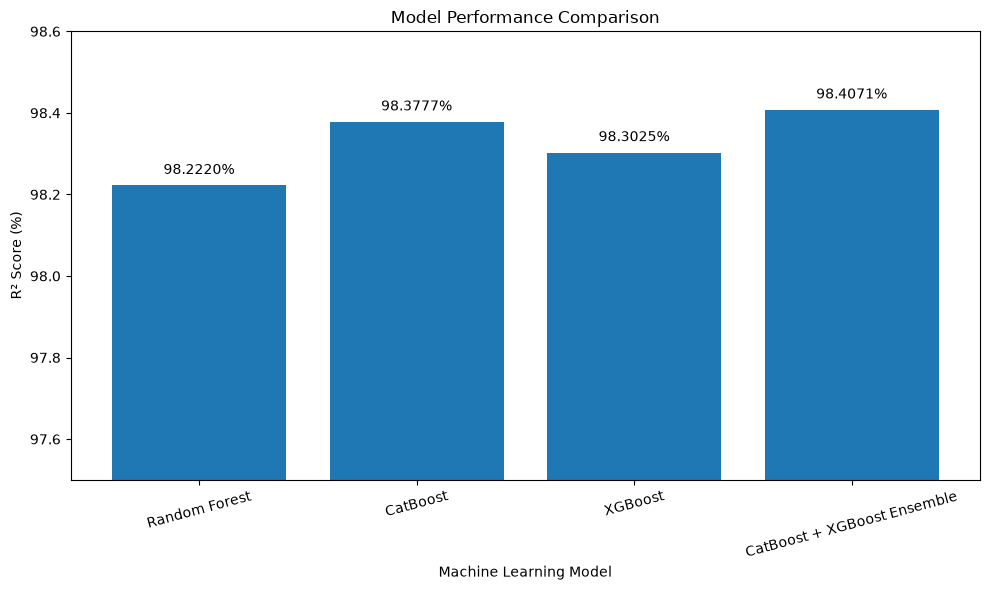

In [19]:
# ============================================================
# CELL 18 — MODEL PERFORMANCE COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

models = comparison["Model"]
r2_scores = comparison["Performance (%)"]

bars = plt.bar(models, r2_scores)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score (%)")
plt.ylim(97.5, 98.6)

# Add values above bars
for bar, value in zip(bars, r2_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.4f}%",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

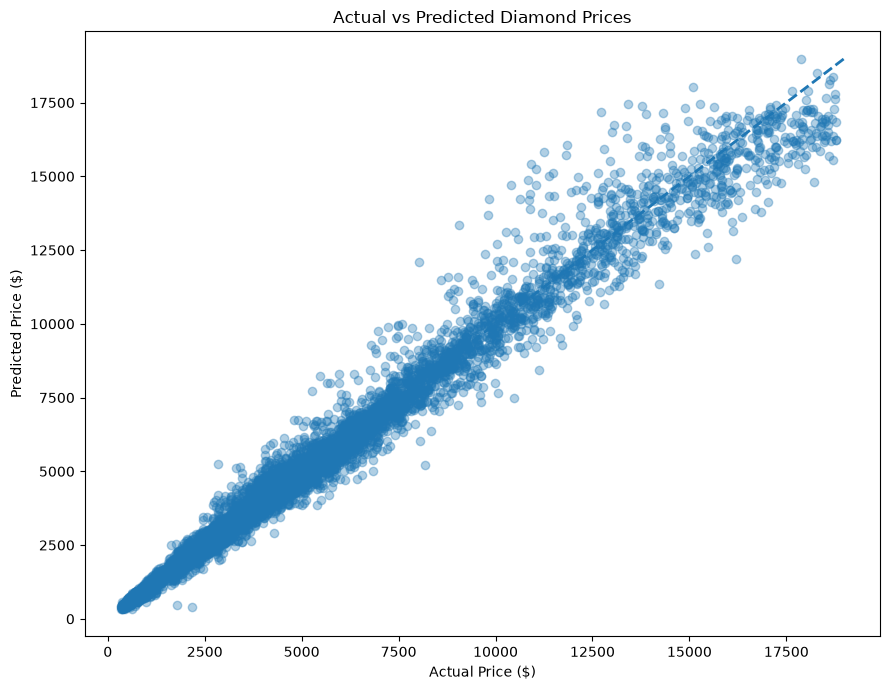

In [20]:
# ============================================================
# CELL 19 — ACTUAL VS PREDICTED PRICE
# ============================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    ensemble_pred,
    alpha=0.35
)

# Perfect prediction line
min_price = min(y_test.min(), ensemble_pred.min())
max_price = max(y_test.max(), ensemble_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    linewidth=2
)

plt.title("Actual vs Predicted Diamond Prices")
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")

plt.tight_layout()
plt.show()

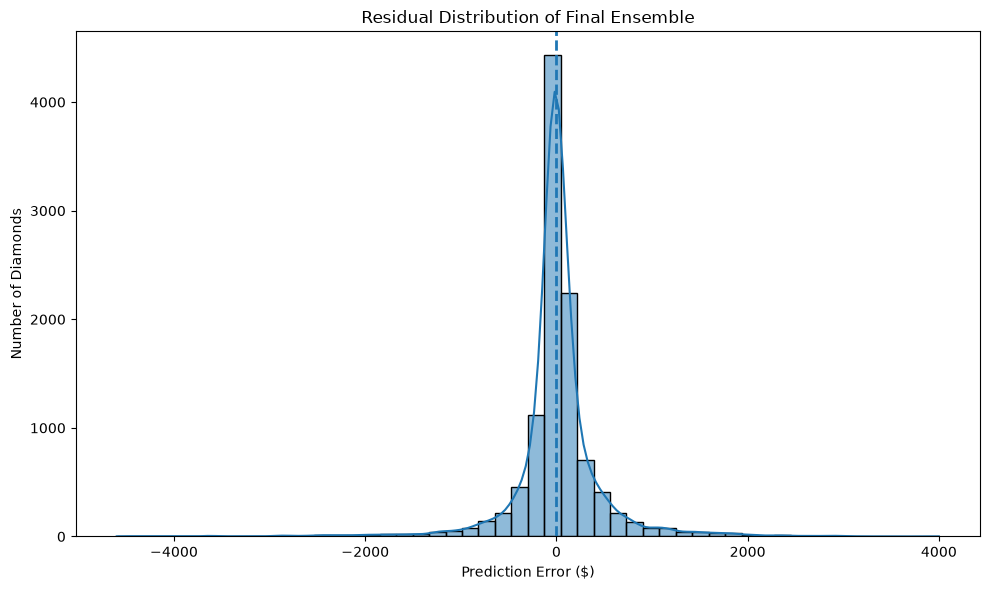

In [21]:
# ============================================================
# CELL 20 — RESIDUAL DISTRIBUTION
# ============================================================

residuals = y_test - ensemble_pred

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2
)

plt.title("Residual Distribution of Final Ensemble")
plt.xlabel("Prediction Error ($)")
plt.ylabel("Number of Diamonds")

plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# CELL 21 — FINAL MODEL PERFORMANCE SUMMARY
# ============================================================

print("=" * 70)
print("FINAL DIAMOND PRICE PREDICTION MODEL")
print("=" * 70)

print("\nModel:")
print("CatBoost + XGBoost Weighted Ensemble")

print("\nEnsemble Weights:")
print("CatBoost : 55%")
print("XGBoost  : 45%")

print("\nFinal Performance:")
print(f"R² Score    : {ensemble_r2:.6f}")
print(f"Performance : {ensemble_r2 * 100:.4f}%")
print(f"MAE         : ${ensemble_mae:,.2f}")
print(f"RMSE        : ${ensemble_rmse:,.2f}")

print("\n" + "=" * 70)
print("MODEL STATUS: FINAL")
print("=" * 70)

FINAL DIAMOND PRICE PREDICTION MODEL

Model:
CatBoost + XGBoost Weighted Ensemble

Ensemble Weights:
CatBoost : 55%
XGBoost  : 45%

Final Performance:
R² Score    : 0.984071
Performance : 98.4071%
MAE         : $257.31
RMSE        : $492.73

MODEL STATUS: FINAL


In [23]:
# ============================================================
# CELL 22 — SAMPLE DIAMOND PRICE PREDICTION
# ============================================================

# Sample diamond
sample_diamond = pd.DataFrame({
    "carat": [1.00],
    "cut": ["Ideal"],
    "color": ["G"],
    "clarity": ["VS2"],
    "depth": [61.5],
    "table": [55.0],
    "x": [6.40],
    "y": [6.40],
    "z": [3.94]
})

# CatBoost prediction
sample_cat_pred = cat_model.predict(sample_diamond)[0]

# XGBoost preprocessing
sample_xgb = preprocessor.transform(sample_diamond)

# XGBoost prediction
sample_xgb_pred = xgb_model.predict(sample_xgb)[0]

# Weighted ensemble prediction
sample_final_pred = (
    0.55 * sample_cat_pred +
    0.45 * sample_xgb_pred
)

print("=" * 60)
print("DIAMOND PRICE PREDICTION")
print("=" * 60)

display(sample_diamond)

print(f"\nCatBoost Prediction : ${sample_cat_pred:,.2f}")
print(f"XGBoost Prediction  : ${sample_xgb_pred:,.2f}")
print(f"Final Prediction    : ${sample_final_pred:,.2f}")

DIAMOND PRICE PREDICTION


,carat,cut,color,clarity,depth,table,x,y,z
0,1.0,Ideal,G,VS2,61.5,55.0,6.4,6.4,3.94



CatBoost Prediction : $6,148.16
XGBoost Prediction  : $6,272.66
Final Prediction    : $6,204.18


# Conclusion

This project developed a machine learning system for diamond price prediction using the standard diamond dataset.

Three individual regression models were evaluated:

- Random Forest
- CatBoost
- XGBoost

The final model combines CatBoost and XGBoost using a weighted ensemble approach, with 55% weight assigned to CatBoost and 45% to XGBoost.

## Final Model Performance

| Metric | Result |
|---|---:|
| R² Score | 0.984071 |
| Performance | 98.4071% |
| MAE | $257.31 |
| RMSE | $492.73 |

The CatBoost-XGBoost ensemble achieved the best overall performance among the tested models.

The final model can take diamond characteristics such as carat, cut, color, clarity, depth, table, and dimensions as input and estimate the expected diamond price.

## Key Findings

1. Carat weight has a strong relationship with diamond price.
2. Cut, color, and clarity also contribute to price prediction.
3. Individual machine learning models achieved high predictive performance.
4. Combining CatBoost and XGBoost improved the overall prediction performance.
5. The final ensemble achieved an R² score of 98.4071%.

## Final Model

**CatBoost (55%) + XGBoost (45%)**

This ensemble is selected as the final diamond price prediction model.

In [24]:

# ==========================================
# SAVE FINAL DIAMOND PRICE PREDICTION MODELS
# ==========================================

import os
import joblib

# Create models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save CatBoost model
cat_model.save_model(
    "../models/catboost_diamond_model.cbm"
)

# Save XGBoost model
joblib.dump(
    xgb_model,
    "../models/xgboost_diamond_model.pkl"
)

# Save XGBoost preprocessing
joblib.dump(
    preprocessor,
    "../models/diamond_preprocessor.pkl"
)

# Save ensemble configuration
ensemble_config = {
    "catboost_weight": 0.55,
    "xgboost_weight": 0.45,
    "model_name": "CatBoost + XGBoost Ensemble"
}

joblib.dump(
    ensemble_config,
    "../models/ensemble_config.pkl"
)

print("All models saved successfully!")
print("Saved inside the models folder.")


All models saved successfully!
Saved inside the models folder.


In [25]:

print("PREPROCESSOR INPUT FEATURES:")
print(list(preprocessor.feature_names_in_))

print("\nCATEGORICAL FEATURES:")
print(list(preprocessor.transformers_[0][2]))

print("\nNUMERICAL FEATURES:")
print(list(preprocessor.transformers_[1][2]))

print("\nENSEMBLE WEIGHTS:")
print(ensemble_config)


PREPROCESSOR INPUT FEATURES:
['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z']

CATEGORICAL FEATURES:
['cut', 'color', 'clarity']

NUMERICAL FEATURES:
['carat', 'depth', 'table', 'x', 'y', 'z']

ENSEMBLE WEIGHTS:
{'catboost_weight': 0.55, 'xgboost_weight': 0.45, 'model_name': 'CatBoost + XGBoost Ensemble'}
